<a href="https://colab.research.google.com/github/villsydican/machine-learning-project/blob/main/Chart_annalysis_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import os
import io
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from google.auth import default
from PIL import Image

# 1. Authenticate & Build Drive API
auth.authenticate_user()
creds, _ = default()
drive_service = build('drive', 'v3', credentials=creds)

# 2. Path to your manually created dataset folder
output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

def download_and_slice(file_id, file_name, rows, cols, label_mapping, prefix):
    print(f"📥 Downloading: {file_name}...")
    request = drive_service.files().get_media(fileId=file_id)
    local_path = f"/tmp/{file_id}.jpg"

    with open(local_path, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request)
        done = False
        while not done:
            status, done = downloader.next_chunk()

    img = Image.open(local_path).convert('RGB')
    w, h = img.size
    cell_w, cell_h = w / cols, h / rows
    count = 0

    for r in range(rows):
        for c in range(cols):
            label = label_mapping.get((r, c))
            if not label:
                continue
            crop = img.crop((
                int((c + 0.08) * cell_w), int((r + 0.18) * cell_h),
                int((c + 0.92) * cell_w), int((r + 0.78) * cell_h)
            )).resize((128, 128))

            save_path = os.path.join(output_dir, label, f"{prefix}_r{r}_c{c}.jpg")
            crop.save(save_path)
            count += 1

    print(f"✅ Sliced & sorted {count} tiles from {file_name}")

# 3. Process each sheet into your manual folders
download_and_slice(
    "1BViimj3mJ-lnL-M79d0QkfOv56AX2BrK", "Bullish candlestick pattern.jpg",
    3, 3, {(r, c): 'buy' for r in range(3) for c in range(3)}, "bullish_9"
)

download_and_slice(
    "1Vkj8OA80pGCvJO8sIN1QY_MP9jEHB1yA", "Candlestick signals",
    2, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'sell', (0,3): 'sell', (1,0): 'buy', (1,1): 'buy', (1,2): 'buy', (1,3): 'hold'}, "signals_8"
)

download_and_slice(
    "1GLPPljf91i74zHnMfGtUixI4g8CoIyZr", "TRADING PSYCHOLOGY.jpg",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'sell', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'sell', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "psych_16"
)

download_and_slice(
    "1kj43Dk9YyS9stuEWuG70bDoAbOY7PpmO", "Take Your Binary Options Trading",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'buy', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'buy', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "binary_16"
)

download_and_slice(
    "15sUVHLacRm-3-AzpLHP0CwswZl22p2bD", "Trade Smarter with Our Binary Options Strategy PDF.jpg",
    3, 5, {(r, c): 'sell' for r in range(3) for c in range(5)}, "bearish_15"
)

print("\n🎉 Population complete! Folder counts:")
for cls in ['buy', 'sell', 'hold']:
    print(f"📂 {cls}/ -> {len(os.listdir(os.path.join(output_dir, cls)))} images")

📥 Downloading: Bullish candlestick pattern.jpg...


✅ Sliced & sorted 9 tiles from Bullish candlestick pattern.jpg
📥 Downloading: Candlestick signals...
✅ Sliced & sorted 8 tiles from Candlestick signals
📥 Downloading: TRADING PSYCHOLOGY.jpg...
✅ Sliced & sorted 16 tiles from TRADING PSYCHOLOGY.jpg
📥 Downloading: Take Your Binary Options Trading...
✅ Sliced & sorted 16 tiles from Take Your Binary Options Trading
📥 Downloading: Trade Smarter with Our Binary Options Strategy PDF.jpg...
✅ Sliced & sorted 15 tiles from Trade Smarter with Our Binary Options Strategy PDF.jpg

🎉 Population complete! Folder counts:
📂 buy/ -> 227 images
📂 sell/ -> 236 images
📂 hold/ -> 201 images


In [45]:
#Generating the images using python
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
for cls in ['buy', 'sell', 'hold']:
  os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

def render_candles(candles, save_path, dark_mode=False):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  bg_color = '#12161c' if dark_mode else '#ffffff'
  bull_color = '#26a69a' if dark_mode else '#16a34a'
  bear_color = '#ef5350' if dark_mode else '#dc2626'
  fig.patch.set_facecolor(bg_color)
  ax.set_facecolor(bg_color)
  for idx, (o, h, l, c) in enumerate(candles):
    color = bull_color if c >= o else bear_color
    #Wick generation
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    #Body generation
    lower = min(o, c)
    height = max(abs(c - o), 0.15) #Minimum visible thickness for Doji
    react = Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(react)
  all_lows = [x[2] for x in candles]
  all_highs = [x[1] for x in candles]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(save_path, dpi=100, facecolor=bg_color)
  plt.close(fig)

# Pattern Generators (each building 4 trend candles + key signal candle)
def generate_buy_pattern():
  pattern_type = random.choice(['hammer', 'bullish_engulfing', 'morning_star', 'three_white_soldiers'])
  price = random.uniform(50, 100)
  candles = []
  if pattern_type == 'hammer':
    # 4 bearish downtrend candles + long lower-wick hammer
    for _ in range (4):
      o = price
      c = o - random.uniform(1.2, 3.0)
      h = o + random.uniform(0.2, 1.0)
      l = c - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c))
      price = c
    o = price
    c = o + random.uniform(0.4, 1.2)
    h = c + random.uniform(0.0, 0.3)
    l = o - random.uniform(3.5, 6.5)
    candles.append ((o, h, l, c))
  elif pattern_type == 'bullish_engulfing':
    # 3 downtrend + 1 small red + 1 large green engulfing candle
    for _ in range (3):
      o = price
      c = o - random.uniform(1.0, 2.5)
      candles.append((o, o + 0.6, c - 0.6, c))
      price = c
    o1 = price
    c1 = o1 - random.uniform(0.8, 1.6)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.1, 0.4)
    c2 = o1 + random.uniform(1.0, 2.5)
    candles.append((o2, c2 + 0.5, o2 - 0.4, c2))

  elif pattern_type == 'morning_star':
    # 2 downtrend + 1 big red + 1 small star + big green
    for _ in range (2):
      o = price
      c = o - random.uniform(1.0, 2.0)
      candles.append ((o, o + 0.5, c - 0.5, c))
      price = c
    o1, c1 = price, price - random.uniform(2.5, 4.0)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = max(o2, c2) + 0.2
    c3 = o1 - random.uniform(0.0, 0.8)
    candles.append((o3, c3 + 0.5, o3 - 0.3, c3))
  else: # drawing three white soldiers
    for _ in range (2):
      o = price
      c = o - random.uniform(1.2, 2.5)
      candles.append((o, o + 0.5, c - 0.5, c))
      price = c
    for _ in range (3):
      o = price + random.uniform(0.1, 0.4)
      c = o + random.uniform(1.8, 3.2)
      candles.append((o, c + 0.4, o - 0.3, c))
      price = c

  return candles

def generate_sell_pattern():
  pattern_type = random.choice(['shooting_star', 'bearish_engulfing', 'evening_star', 'three_black_crows'])
  price = random.uniform(50, 100)
  candles = []

  if pattern_type == 'shooting_star':
    for _ in range(4):
      o = price
      c = o + random.uniform(1.2, 3.0)
      h = c + random.uniform(0.2, 1.0)
      l = o - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c ))
      price = c
    o = price
    c  = o - random.uniform(0.4, 1.2)
    h = o + random.uniform(3.5, 6.5)
    l = c - random.uniform(0.0, 0.3)
    candles.append((o, h, l, c))
  elif pattern_type == 'bearish_engulfing' :
    for _ in range (3):
      o = price
      c = o + random.uniform(1.0, 2.5)
      candles.append((o, c + 0.6, o - 0.6, c))
      price = c
    o1 =  price
    c1 = o1 + random.uniform(0.8, 1.6)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1 ))
    o2 = c1 + random.uniform(0.1, 0.4)
    c2 = o1 - random.uniform(1.0, 2.5)
    candles.append((o2, o2 + 0.4, c2 - 0.5, c2))
  elif pattern_type == 'evening_star':
    for _ in range(2):
      o = price
      c = o + random.uniform(1.0, 2.0)
      candles.append((o, c + 0.5, o - 0.5, c)) # Fixed undefined o1 to o
      price = c
    o1, c1 = price, price + random.uniform(2.5, 4.0)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1))
    o2 = c1 + random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = min(o2, c2) - 0.2
    c3 = o1 + random.uniform(0.0, 0.8)
    candles.append((o3, o3 + 0.3, c3 - 0.5, c3))
  else : # three_black_crows
    for _ in range (2):
      o = price
      c = o + random.uniform(0.1, 0.4)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
    for _ in range(3):
      o = price - random.uniform(0.1, 0.4)
      c = o - random.uniform(1.8, 3.2)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
  return candles

# Generating images for holding or equilibrium patterns
# Sideways consolidation with dojis and Spinning tops
def generate_hold_pattern():
  base_price = random.uniform(50, 100 )
  candles = []
  for _ in range(5):
    o = base_price + random.uniform(-0.8, 0.8)
    c = o + random.uniform(-0.4, 0.4)
    h = max(o, c) + random.uniform(0.8, 2.2)
    l = min(o, c) - random.uniform(0.8, 2.2)
    candles.append((o, h, l, c))
  return candles

# Generating 200 images per class
samples_per_class = 200
print (f"Generating {samples_per_class * 3} synthetic candlestick images.....")

for i in range (samples_per_class):
  dark = random.choice([True, False]) # Mixing the light and dark trading themes
  render_candles(generate_buy_pattern(), os.path.join(output_dir, 'buy', f'synth_buy_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_sell_pattern(), os.path.join(output_dir, 'sell', f'synth_sell_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_hold_pattern(), os.path.join(output_dir, 'hold', f'synth_hold_{i:03d}.png'), dark_mode=dark)
print ("===========================")
print ("\n Synthetic dataset generation complet!! Updated Folde Total: ")
for cls in ['buy', 'sell', 'hold']:
  total = len(os.listdir(os.path.join(output_dir, cls)))
  print(f"{cls}/ -> {total} total images")

Generating 600 synthetic candlestick images.....

 Synthetic dataset generation complet!! Updated Folde Total: 
buy/ -> 227 total images
sell/ -> 236 total images
hold/ -> 201 total images


In [46]:
import tensorflow as tf
data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
batch_size = 16
img_height, img_width = 128, 128
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset = "training",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure




)
#loading the validation Dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure
)
class_names = train_ds.class_names
print (f"\n Detected Model Classes : {class_names}")


Found 664 files belonging to 3 classes.
Using 532 files for training.
Found 664 files belonging to 3 classes.
Using 132 files for validation.

 Detected Model Classes : ['buy', 'hold', 'sell']


In [47]:

from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')#output layer


])
#Compling the model
model.compile(
    optimizer='adam',
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)
#Printing the summary of the model layers and tool parameters
model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
#Training and testing the model performances
epochs = 15
print (f"Starting training for {epochs} epochs....\n")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
print ("\Training completed!!!!")
model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model.save(model_path)
print(f"Model saved to: {model_path} Successfully")

Starting training for 15 epochs....

Epoch 1/15


<>:9: SyntaxWarning: invalid escape sequence '\T'
<>:9: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_720/364429844.py:9: SyntaxWarning: invalid escape sequence '\T'
  print ("\Training completed!!!!")


34/34 ━━━━━━━━━━━━━━━━━━━━ 14s 367ms/step - accuracy: 0.8214 - loss: 0.5507 - val_accuracy: 0.9318 - val_loss: 0.2753
Epoch 2/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 12s 362ms/step - accuracy: 0.9699 - loss: 0.0966 - val_accuracy: 0.9697 - val_loss: 0.0628
Epoch 3/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 20s 344ms/step - accuracy: 0.9868 - loss: 0.0347 - val_accuracy: 0.9773 - val_loss: 0.1075
Epoch 4/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 12s 359ms/step - accuracy: 0.9981 - loss: 0.0090 - val_accuracy: 0.9848 - val_loss: 0.0760
Epoch 5/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 20s 344ms/step - accuracy: 1.0000 - loss: 0.0023 - val_accuracy: 0.9848 - val_loss: 0.0871
Epoch 6/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 12s 345ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.9848 - val_loss: 0.1307
Epoch 7/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 21s 355ms/step - accuracy: 1.0000 - loss: 2.4599e-04 - val_accuracy: 0.9848 - val_loss: 0.1281
Epoch 8/15
34/34 ━━━━━━━━━━━━━━━━━━━━ 12s 359ms/step - accuracy: 1.0000 - loss: 3.0456e-04 - val_accurac

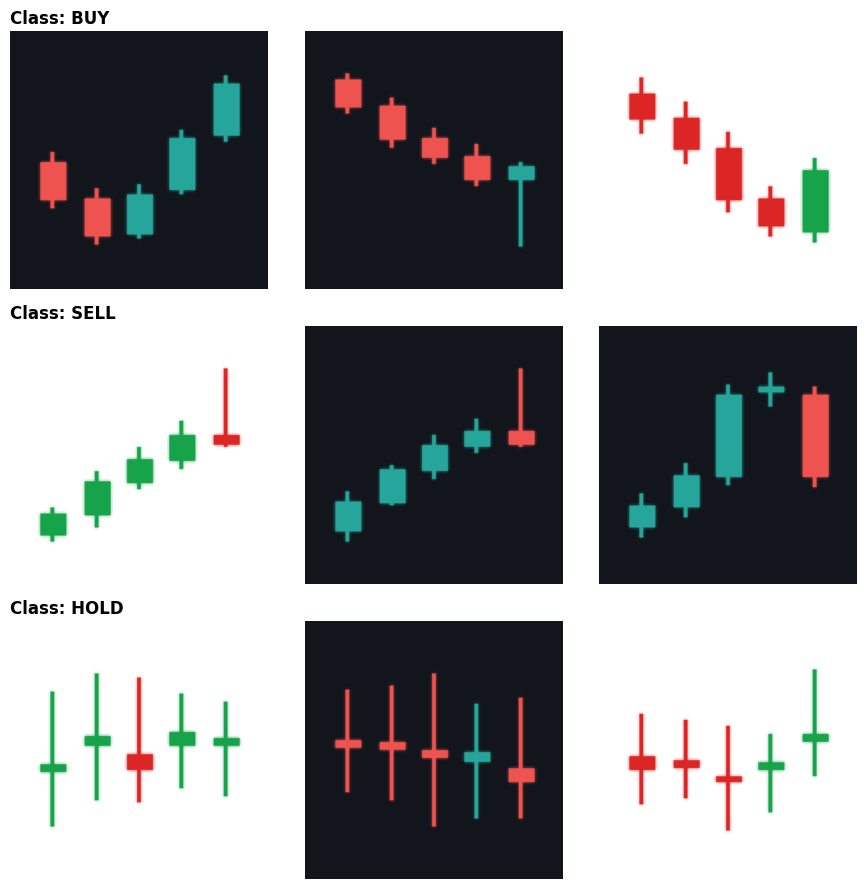

In [49]:
#Visualizing the data generated
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
classes = ['buy', 'sell', 'hold']

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row_idx, cls in enumerate(classes):
  cls_folder = os.path.join(data_dir, cls)
  sample_files = random.sample(os.listdir(cls_folder), 3)
  for col_idx, file_name in enumerate(sample_files):
    img_path = os.path.join(cls_folder, file_name)
    img = mpimg.imread(img_path)
    ax = axes[row_idx, col_idx]
    ax.imshow(img)
    ax.axis('off')
    if col_idx == 0:
      ax.set_title(f"Class: {cls.upper()}", fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

In [50]:
#Feeding the fetched data into the model
import tensorflow as tf
from tensorflow.keras.models import load_model

model = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model = load_model(model)

print ("Model loaded successfully")
class_names = ['buy', 'hold', 'sell']
if df_stock is not None and not df_stock.empty and len(df_stock) >= 5:
  recent_candles = df_stock.tail(5)
  candles_tuple = [(row['Open'], row['High'], row['Low'], row['Close']) for _, row in recent_candles.iterrows()]
  #REndering into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles_tuple):
    color = '#16a34a' if c>= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Predicting the data to buy/sell/hold
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)

  preds = model.predict(img_array) [0]
  best_idx = preds.argmax()
  print (f"\n Signals for {ticker_symbol}: {class_names[best_idx].upper()} ({preds[best_idx] * 100:.2f}%)")





Model loaded successfully


In [51]:
#LOADING LIVE MARKET DATA FROM ALPHA_VANTAGE_STOCK_MARKET
import io
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
API_KEY = "5SSM7TV3NATANWD6"
#Fetching the data




Trget directory comfirmed at /content/drive/MyDrive/candlestick_dataset


In [57]:
#Watchlist Execution loop
watchlist = ["AAPL", "MSFT", "GOOGL", "TSLA"]
total_generated = 0

for ticker in watchlist:
  df_stock = fetch_alpha_vantage_data(ticker, API_KEY)


  if df_stock is not None and len(df_stock) >= 10:
    source_counts = {'buy':0, 'hold':0, 'sell':0}
    for i in range(5, len(df_stock) - 3):
      window = df_stock.iloc[i-5:i]
      future_close = df_stock.iloc[i + 3]['Close']
      current_close = window.iloc[-1]['Close']
      pct_change = (future_close - current_close) / current_close
      if pct_change > 0.005:
        label = 'buy'
      elif pct_change < -0.005:
        label = 'sell'
      else:
        label = 'hold'
        candles_tuple = list(window[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))
        render_and_save_tile(candles_tuple, label, ticker, i)
        source_counts[label] += 1
        total_generated += 1
    print (f" -> Generated | Buy: {saved_counts['buy']} | Hold: {saved_counts['hold']} | Sell:{saved_counts['sell']}")


Failed to fetch data for AAPL: 'Time Series (Daily)'
Failed to fetch data for MSFT: 'Time Series (Daily)'
Failed to fetch data for GOOGL: 'Time Series (Daily)'
Failed to fetch data for TSLA: 'Time Series (Daily)'


In [53]:
#Temporal Data
import pandas as pd
dummy_df = pd.DataFrame({
    'Open': [100, 102, 101, 104, 108, 120, 110],
    'High': [103, 104, 105, 109, 115, 117, 118],
    'Low':  [99, 100, 100, 103, 108, 119, 98],
    'Close':[102, 101, 104, 108, 114, 120, 99]
})
print (dummy_df)

   Open  High  Low  Close
0   100   103   99    102
1   102   104  100    101
2   101   105  100    104
3   104   109  103    108
4   108   115  108    114
5   120   117  119    120
6   110   118   98     99


In [ ]:
#Notification tab
import io
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart
from email.mime.image import MIMEImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import requests
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
import time
import yfinance as yf


#USing telegram for model configuration and getting the news
TELEGRAM_TOKEN = "9110780049:AAFh_gpwJK2ncGF8kL-IZTZec_h17liLBfk"
CHAT_ID = "8633134929"
CONFIDENCE_THRESHOLD = 70.0

#Tracking the alerts to avoid the repetitions
last_sent_signals ={}
def process_and_alert(ticker, df_stock):
  print (f" Processing started for {ticker}...")
  if df_stock is None or df_stock.empty or len (df_stock) < 5:
    print(f"Insufficient data for {ticker}.")
    return
  recent = df_stock.tail(5)
  latest_close = recent.iloc[-1]['Close']
  candles = list(recent[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))

  #Rendering the charts into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')

  for idx, (o, h, l , c) in enumerate(candles):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    rect = patches.Rectangle((idx - 0.28, min(o, c)), 0.56, max(abs(c - o), 0.15), facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  pad = (max(x[1] for x in candles) - min(x[2] for x in candles))
  ax.set_ylim(min(x[2] for x in candles) - pad, max(x[1] for x in candles) + pad)
  ax.set_xlim(0.7, len(candles) - 0.3)
  ax.axis("off")
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Running the CNN model for prediction
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
  predictions = model.predict(img_array, verbose=0) [0]
  predicted_idx = np.argmax(predictions)
  signal = class_names[predicted_idx].upper()
  confidence = predictions[predicted_idx] * 100

  print (f" {ticker} -> {signal} ({confidence:2f}%)")

  #Sending the telegram alert
  if signal in ['BUY', 'HOLD', 'SELL'] and confidence >= CONFIDENCE_THRESHOLD:
    if last_sent_signals.get(ticker) == signal:
      return #Skipping if the exact signal was already sent
    url =  f"https://api.telegram.org/bot{TELEGRAM_TOKEN}/sendPhoto"
    caption = (
        f"🚨 *Trading Alert: {signal}*\n\n"
        f". *Asset: * '{ticker}'\n"
        f". *Confidence: * *{confidence:.2f}%*\n"
        f". *Latest Close:* '{latest_close}' \n\n"
        f"*Model Probabilities:*\n"
        f"🟢 BUY: {predictions[0]*100:.2f}%\n"
        f"🟡 HOLD: {predictions[1]*100:.2f}%\n"
        f"🔴 SELL: {predictions[2]*100:.2f}%\n"
    )
    buf.seek(0)
    files = {"photo": ("candlestick_tile.png", buf, "image/png")}
    data = {"chat_id": CHAT_ID, "caption": caption}

    response = requests.post(url, data=data, files=files)
    print("Telegram Response:", response.json())
    if response.json().get("ok"):
      print(f"📲 Telegram alert sent for {ticker}!")
      last_sent_signals[ticker] = signal
  else:
    last_sent_signals[ticker] = None
def fetch_stock_data(ticker):
  print(f"Fetching live data for {ticker}...")
  df = yf.download(ticker, period="1mo", interval="1d",  auto_adjust=True, progress=False)
  if df.empty:
    print(f"No data found for {ticker}")
    return None
  if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)
  return df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()




watchlist = ["AAPL", "MSFT", "GOOGL", "TSLA"]
for ticker in watchlist:
  df_stock = fetch_stock_data(ticker)
  process_and_alert(ticker, df_stock)
  time.sleep(2)





In [55]:
import os

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

print("📊 Verifying all files in your dataset folders:")
total_files = 0
for cls in ['buy', 'sell', 'hold']:
    cls_path = os.path.join(data_dir, cls)
    if os.path.exists(cls_path):
        files = os.listdir(cls_path)
        print(f"📂 {cls}/ -> {len(files)} total images found")
        total_files += len(files)
    else:
        print(f"⚠️ Folder missing: {cls}")

print(f"\n🎉 Grand Total across all classes: {total_files} images ready for training!")

📊 Verifying all files in your dataset folders:
📂 buy/ -> 227 total images found
📂 sell/ -> 236 total images found
📂 hold/ -> 201 total images found

🎉 Grand Total across all classes: 664 images ready for training!


In [63]:
#Testing the yfince API
import yfinance as yf
import curl_cffi
print("YFinance version:", yf.__version__)
print("Curl CFFI version:", curl_cffi.__version__)
ticker = 'AAPL'

print(f"Fetching data for {ticker}.....")
df = yf.download(ticker, period="1mo", interval="1d",  auto_adjust=True, progress=False)
if df.empty:
  print(f"No data found for {ticker}")
else:
  print("Download succefully!!")
  print(df.head())
  print("Dataset shape:", df.shape)

ERROR:yfinance:Failed to get ticker 'AAPL' reason: Impersonating chrome152 is not supported
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['AAPL']: ImpersonateError('Impersonating chrome152 is not supported')


YFinance version: 0.2.66
Curl CFFI version: 0.17.0
Fetching data for AAPL.....
No data found for AAPL


In [64]:
#Testing the curl_cffi
import curl_cffi
print("Version:", curl_cffi.__version__)
print("Location:", curl_cffi.__version__)

#Testing the brower impersation independently
session = curl_cffi.requests.Session(
    impersonate='chrome152'

)
print("chrome 152 impersonation successful!!")

Version: 0.17.0
Location: 0.17.0
chrome 152 impersonation successful!!


In [65]:
from math import e
df = yf.download(ticker, period="1mo", interval="1d",  auto_adjust=True, progress=False, session=session)
if not df.empty:
  print("Success! Data downloaded.")
  print(df.tail())
  print("Dataset shape:", df.shape)
else:
  print("Unable to load...")

print(df.head())

ERROR:yfinance:Failed to get ticker 'AAPL' reason: Impersonating chrome152 is not supported
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['AAPL']: ImpersonateError('Impersonating chrome152 is not supported')


Unable to load...
Empty DataFrame
Columns: [(Adj Close, AAPL), (Close, AAPL), (High, AAPL), (Low, AAPL), (Open, AAPL), (Volume, AAPL)]
Index: []


In [62]:
import os

model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'

if os.path.exists(model_path):
    print("✅ Model file found!")
else:
    print("⚠️ Model file not found at that path. You need to run your training cell first so it can save the model!")

✅ Model file found!
